In [2]:
# 1. Ajustar el modelo final con k=3 clusters
k_optimo = 3
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

# 2. Análisis de Centroides y Perfiles
perfiles = df.groupby('Cluster')[features_cluster + ['Churn']].mean().reset_index()

# Mapeo de nombres ejecutivos/descriptivos a los Clusters
nombres_clusters = {
    0: "Cluster 0: Clientes de Bajo Uso y Alto Soporte (Alto Riesgo)",
    1: "Cluster 1: Usuarios Corporativos Intensivos (Alta Retención)",
    2: "Cluster 2: Clientes Estándar / Uso Moderado"
}
df['Perfil_Nombre'] = df['Cluster'].map(nombres_clusters)

print("=== CENTROIDES Y METRICAS PROMEDIO POR CLUSTER ===")
print(perfiles)

# 3. Guardar el Modelo de Clustering y el Escalador para la App
joblib.dump(kmeans_final, '../models/kmeans_model.pkl')
joblib.dump(scaler, '../models/cluster_scaler.pkl')
joblib.dump(features_cluster, '../models/cluster_features.pkl')

print("\n¡Modelo K-Means y Escalador guardados en la carpeta 'models/'!")

=== CENTROIDES Y METRICAS PROMEDIO POR CLUSTER ===
   Cluster       Edad  Antiguedad_Meses  Soporte_Tickets  Uso_Diario_Min  \
0        0  37.921414         36.873181         2.045738       44.166047   
1        1  38.054019         35.247839         1.958081       51.378516   
2        2  37.742690         34.754386         2.132554        1.596221   

   Monto_Mensual  Costo_Por_Minuto     Churn  
0      94.979315          5.734355  0.173389  
1     229.304340          9.963592  0.261236  
2     217.675035         97.595676  0.479532  

¡Modelo K-Means y Escalador guardados en la carpeta 'models/'!


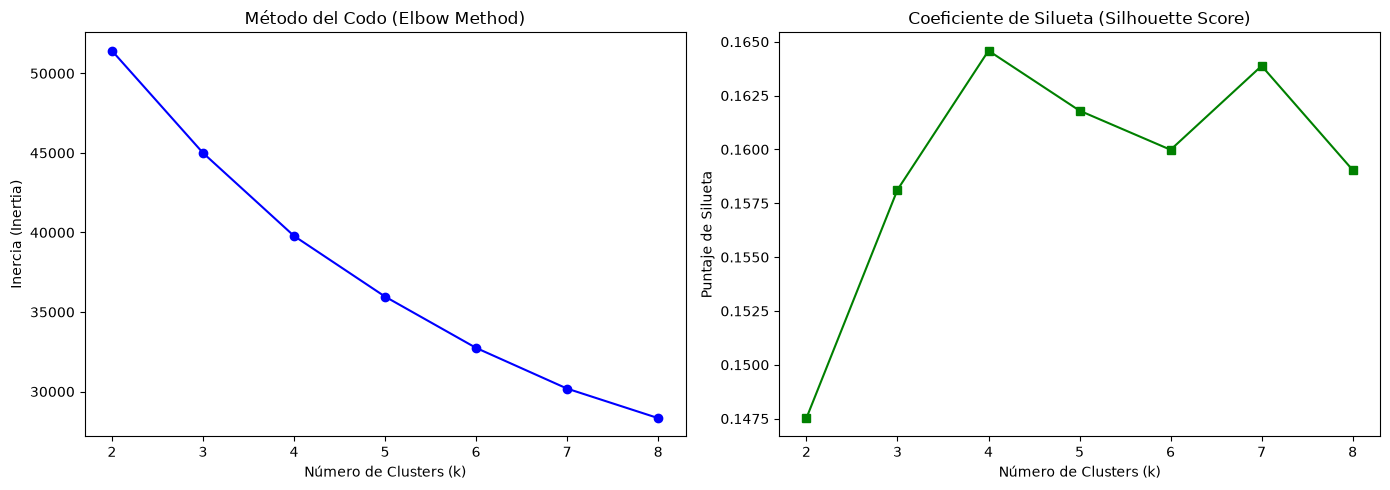

Puntajes de Silueta por k: {2: 0.148, 3: 0.158, 4: 0.165, 5: 0.162, 6: 0.16, 7: 0.164, 8: 0.159}


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Cargar el dataset limpio
df = pd.read_csv('../data/datacloud_churn_clean.csv')

# 2. Seleccionar características continuas para la segmentación
features_cluster = ['Edad', 'Antiguedad_Meses', 'Soporte_Tickets', 'Uso_Diario_Min', 'Monto_Mensual', 'Costo_Por_Minuto']
X_cluster = df[features_cluster]

# 3. Escalado Estándar (Requisito fundamental para K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# 4. Evaluación del Método del Codo y Silueta (k de 2 a 8)
inertia = []
silhouette_scores = []
K_range = range(2, 9)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Visualización gráfica
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico del Codo
ax[0].plot(K_range, inertia, marker='o', color='b')
ax[0].set_title('Método del Codo (Elbow Method)')
ax[0].set_xlabel('Número de Clusters (k)')
ax[0].set_ylabel('Inercia (Inertia)')

# Gráfico del Coeficiente de Silueta
ax[1].plot(K_range, silhouette_scores, marker='s', color='g')
ax[1].set_title('Coeficiente de Silueta (Silhouette Score)')
ax[1].set_xlabel('Número de Clusters (k)')
ax[1].set_ylabel('Puntaje de Silueta')

plt.tight_layout()
plt.show()

print("Puntajes de Silueta por k:", dict(zip(K_range, [round(s, 3) for s in silhouette_scores])))